# code_095 · Evaluating discovered groups

**Book:** section 19.3. A self-contained clustering-and-anomaly laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_19_GUIDE.md), [run evidence](../CHAPTER_19_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_095).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1995;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1995


<a id="evaluation"></a>
## Ask three different evaluation questions

Generate training300/development100/final200 independent cases from three declared Gaussian operating regimes, with four redundant noisy sensors. Fault labels are Bernoulli sigmoid(-2+regime_effect+.5*first_descriptor), regime effects[-1,1.5,-.5]. This generated relationship permits a downstream audit, not a causal fault interpretation. A training-only scaler and KMeans K[2,3,5]/n_init20 supply partitions. Record training silhouette and external generator-regime ARI separately. Fit fixedC1logistic models on standardized raw sensors alone or sensors plus one-hot training-cluster IDs. Clustering uses training features only; it does not need target crossfitting because this fixed preprocessing has no target input. Development Brier selects K for the downstream candidate. Frozen final results for all candidates remain visible without changing that choice. A favorable internal score does not validate a regime name or establish downstream usefulness.


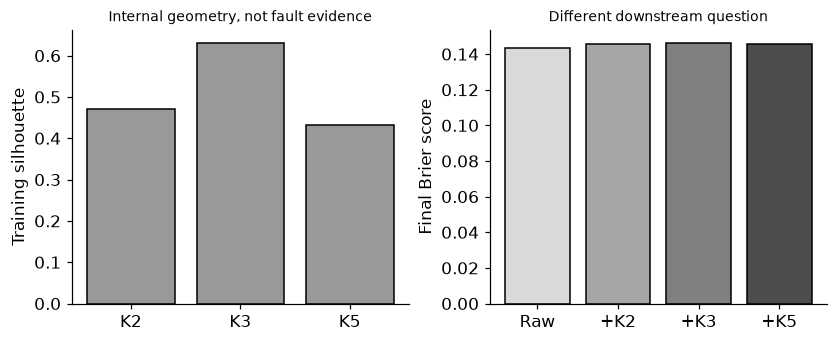

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score,adjusted_rand_score,brier_score_loss,log_loss
from scipy.special import expit
means=np.array([[-2.,0.],[0.,2.],[2.,0.]]);effects=np.array([-1.,1.5,-.5])
def generate(n):
 regime=rng.integers(0,3,n);latent=means[regime]+rng.normal(0,.55,(n,2));a=np.column_stack([latent,latent+rng.normal(0,.15,(n,2))]);b=rng.binomial(1,expit(-2+effects[regime]+.5*latent[:,0]));return a,b,regime
X,y,regime=generate(300);Xd,yd,rd=generate(100);Xt,yt,rt=generate(200);sc=StandardScaler().fit(X);S=sc.transform(X);D=sc.transform(Xd);T=sc.transform(Xt);base=LogisticRegression(C=1,max_iter=300).fit(S,y);base_p=base.predict_proba(T)[:,1];rows=[];fits={}
for k in [2,3,5]:
 km=KMeans(k,n_init=20,random_state=SEED).fit(S)
 def feature(a):return np.column_stack([a,np.eye(k)[km.predict(a)]])
 fit=LogisticRegression(C=1,max_iter=300).fit(feature(S),y);pdv=fit.predict_proba(feature(D))[:,1];p=fit.predict_proba(feature(T))[:,1];rows.append({'k':k,'training_silhouette':float(silhouette_score(S,km.labels_)),'training_generator_regime_ARI':float(adjusted_rand_score(regime,km.labels_)),'development_brier':float(brier_score_loss(yd,pdv)),'final_brier':float(brier_score_loss(yt,p)),'final_log_loss':float(log_loss(yt,p))});fits[k]=(km,fit)
selected=min(rows,key=lambda r:r['development_brier'])['k'];assert selected in [2,3,5];labels=fits[selected][0].labels_;permutation=np.arange(selected)[::-1];assert adjusted_rand_score(labels,permutation[labels])==1;assert np.isfinite(base_p).all()
RESULTS['roles']={'training':300,'development':100,'final':200,'targets_used_to_fit_clusters':False,'selection_metric':'downstream development Brier'};RESULTS['candidates']=rows;RESULTS['selected_k']=selected;RESULTS['raw_sensor_baseline']={'development_brier':float(brier_score_loss(yd,base.predict_proba(D)[:,1])),'final_brier':float(brier_score_loss(yt,base_p)),'final_log_loss':float(log_loss(yt,base_p))};RESULTS['arbitrary_label_permutation_ARI']=1.
fig,axes=plt.subplots(1,2,figsize=(7.5,3));pos=np.arange(3);axes[0].bar(pos,[r['training_silhouette'] for r in rows],color='.6',edgecolor='black');axes[0].set(xticks=pos,xticklabels=['K2','K3','K5'],ylabel='Training silhouette',title='Internal geometry, not fault evidence');axes[1].bar(range(4),[brier_score_loss(yt,base_p)]+[r['final_brier'] for r in rows],color=['.85','.65','.5','.3'],edgecolor='black');axes[1].set(xticks=range(4),xticklabels=['Raw','+K2','+K3','+K5'],ylabel='Final Brier score',title='Different downstream question');plt.show()


<a id="resampling"></a>
## Resample measurements while preserving record identity

For each K, repeat twenty sensor-perturbation fits with added NormalSD.15 in the original declared sensor coordinates. Fit the scaler and clusterer anew on perturbed TRAINING measurements; compare partitions of the same case IDs using ARI. This tests sensitivity to a specified measurement perturbation rather than independently establishing real sensor repeatability. Do not compare arbitrary integer labels directly. A training contingency table compares selected clusters with generator regime annotations, while its row/column counts remain available. Stable groups can still reflect irrelevant geometry, and external agreement alone does not validate a maintenance action. Independent interpretation or prospective downstream evidence is needed for that claim.


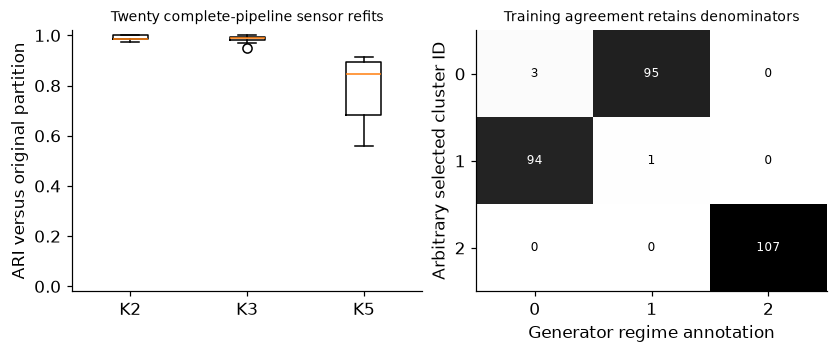

In [3]:
stability=[];values=[]
for k in [2,3,5]:
 scores=[]
 for repeat in range(20):
  perturbed=X+rng.normal(0,.15,X.shape);trans=StandardScaler().fit_transform(perturbed);label=KMeans(k,n_init=10,random_state=SEED+repeat).fit_predict(trans);scores.append(float(adjusted_rand_score(fits[k][0].labels_,label)))
 values.append(scores);stability.append({'k':k,'reruns':20,'mean_ARI':float(np.mean(scores)),'minimum_ARI':float(min(scores)),'maximum_ARI':float(max(scores))})
contingency=np.zeros((selected,3),int)
for a,b in zip(labels,regime):contingency[a,b]+=1
assert contingency.sum()==len(y);np.testing.assert_array_equal(contingency.sum(axis=0),np.bincount(regime,minlength=3));RESULTS['sensor_resampling']=stability;RESULTS['selected_training_contingency']={'rows':'arbitrary selected cluster IDs','columns':'generator regime0/1/2','counts':contingency.tolist(),'independent_interpretation_claimed':False};fig,axes=plt.subplots(1,2,figsize=(7.5,3.1));axes[0].boxplot(values,tick_labels=['K2','K3','K5']);axes[0].set(ylabel='ARI versus original partition',ylim=(-.02,1.02),title='Twenty complete-pipeline sensor refits');im=axes[1].imshow(contingency,cmap='Greys',aspect='auto')
for i in range(selected):
 for j in range(3):axes[1].text(j,i,str(contingency[i,j]),ha='center',va='center',color='white' if contingency[i,j]>contingency.max()/2 else 'black',fontsize=8)
axes[1].set(xticks=range(3),yticks=range(selected),xlabel='Generator regime annotation',ylabel='Arbitrary selected cluster ID',title='Training agreement retains denominators');plt.show()


In [4]:
summary={'example_id':'code_095','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['internal separation versus external agreement', 'training-only clustering in downstream prediction', 'sensor resampling and permutation-invariant stability', 'development selection without final interpretation tuning'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["internal separation versus external agreement", "training-only clustering in downstream prediction", "sensor resampling and permutation-invariant stability", "development selection without final interpretation tuning"], "elapsed_seconds": 0.541, "example_id": "code_095", "hardware": "Darwin arm64 CPU", "results": {"arbitrary_label_permutation_ARI": 1.0, "candidates": [{"development_brier": 0.14046796202113151, "final_brier": 0.14585692078591722, "final_log_loss": 0.4472031549829282, "k": 2, "training_generator_regime_ARI": 0.5830470344652239, "training_silhouette": 0.4714283429677616}, {"development_brier": 0.1393186348673421, "final_brier": 0.14601357141117086, "final_log_loss": 0.44849161675057914, "k": 3, "training_generator_regime_ARI": 0.961994444346516, "training_silhouette": 0.6295820157518648}, {"development_brier": 0.13994995852980568, "final_brier": 0.14539703493103975, "final_log_loss": 0.4507053742301881, "k": 5, "training_